In [82]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import json
import time

import numpy as np
import networkx as nx
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import fleet_opt_core

import src_bilevel as src
import figures

from src_bilevel.rust_bridge import build_rust_network
from src_bilevel.reload import deep_reload
from figures import style
matplotlib.rcParams.update(**style['rcparams'])

## Constrained optimization example

In [83]:
'''
Loading graphs

trips - a graph with trips as nodes and edges to possible successors
locations - a graph representing the physical cost of traveling between
    trip terminals and depots
'''
deep_reload(src)

trips = src.graph.graph_from_json('Data/Unitrans/trips.json')

trips.remove_nodes_from(
    [k for k, n in trips._node.items() if \
     not n['route'] in ['A', 'B', 'C', 'D', 'E', 'F']]
)

locations = src.graph.graph_from_json('Data/Unitrans/locations.json')

locations.remove_node('Secondary Depot')

In [84]:
trips.number_of_nodes()

322

In [118]:
'''
Loading vehicles and ports
'''

with open('Data/vehicle_types_reduced.json', 'r') as f:
    
    vehicles_data = json.load(f)

# for vd in vehicles_data:
#     if "AC-PLUG" in vd['supply_types']:
#         vd['supply_types'].remove("AC-PLUG")

vehicles_data[1]['unit_cost'] = 800000.
vehicles_data[1]['fixed_cost'] = 0.
vehicles_data[1]['annual_cost'] = 0.

vehicle_types = {
    v['type']: src.optimization.Vehicle_Type(**v) for v in vehicles_data
}

with open('Data/port_types_reduced.json', 'r') as f:
    
    ports_data = json.load(f)

ports_data[0]['unit_cost'] = 0.
ports_data[0]['fixed_cost'] = 0.
ports_data[0]['annual_cost'] = 0.

port_types = {
    v['type']: src.optimization.Port_Type(**v) for v in ports_data
}

In [119]:
'''
Making a Python Network
'''
deep_reload(src)

objectives = {
    'Total Cost': src.optimization.Total_Cost(
        schedules_per_period = 365,
        depot_capacity_pricing = {
            # 'Primary Depot': [(i, 1e6) for i in range(25, 100)],
            # 'Secondary Depot': [(i, 1e6) for i in range(25, 100)],
            # 'Primary Depot': [(25, 1e60)],
            # 'Secondary Depot': [(25, 1e60)],
            # 'Secondary Depot': [(40, 1e6)],
        },
    ),
    'Fleet Portion': src.optimization.Minimize_Fleet_Portion(
        included = ['ICEV'],
    ),
}

constraints = {
    'Energy': src.optimization.Energy(),
}


kw = {
    'trips': trips,
    'locations': locations,
    'vehicle_types': vehicle_types,
    'port_types': port_types,
    'constraints': constraints,
    'objectives': objectives,
}

network = src.optimization.Network(**kw)

In [120]:
'''
Running the optimization in Python (Not Reccommended) - This will take
    around 30 minutes
'''
deep_reload(src)

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'seed': 34,
    'max_iter': 100,
    'min_iter': 50,
    'initial_population_size': 300,
    'population_size': 100,
    'crossover_probability': 0.5,
    'mutation_probability': 0.,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = network.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Generating Initial Population

 [------------------->] 100.00%, 186.60 it/s, 1.62 s elapsed, 0.00 s remaining

Optimizing

 [-------------------->] 100.00%, 3.79 it/s, 26.90 s elapsed, 0.00 s remaining
Done in 29.1s  |  101 generations stored


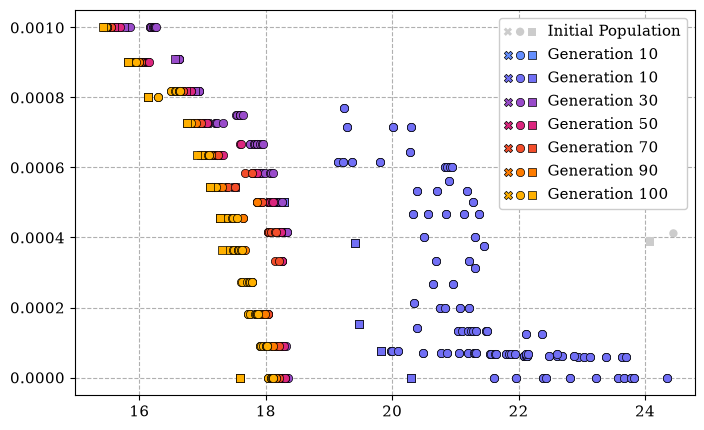

In [121]:
'''
Plotting generations
'''
deep_reload(src)
deep_reload(figures)

fig, ax = plt.subplots(figsize = (8, 5))

show = [10, 100, 300, len(generations) - 1]
show = [10] + list(range(10, len(generations), 20)) + [len(generations) - 1]

cmap = src.plot.Colormap(
    colors = 'ibm', vmin = 0, vmax = len(show) - 1
)

ax = figures.generations_plot(
    ax, generations, 'Total Cost', 'Fleet Portion',
    interval = 200, rank = 100, cmap = cmap, initial = True,
    show = show,
)

kw = {
    # 'xlabel': 'Capital Cost [Million USD]',
    # 'ylabel': 'Daily Cost [Thousand USD]',
}

_ = ax.set(**kw)

kw = {
    'ls': '--',
}

_ = ax.grid(**kw)

In [122]:
py_pop_dict  = src.optimization.population_to_dict(population)

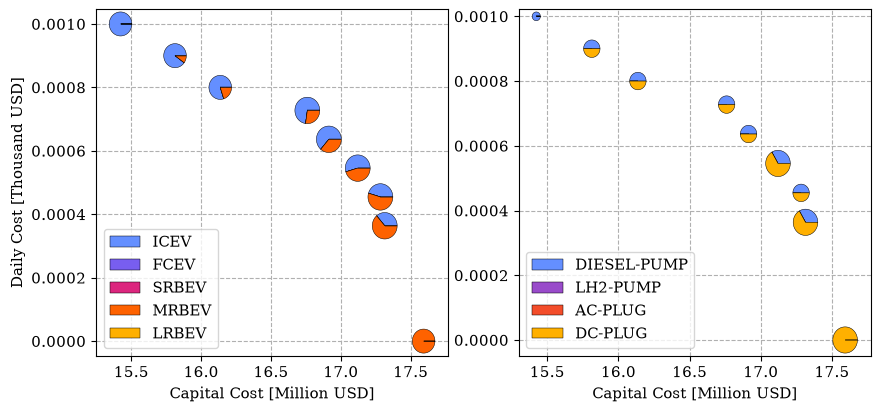

In [123]:
'''
Plotting Pareto Compositions
'''
deep_reload(src)
deep_reload(figures)

matplotlib.rcParams.update(**style['rcparams'])
fig, ax = plt.subplots(1, 2, figsize = (10, 4.5))

n_shown = 100

ax[0] = figures.vehicles_scatter_pie(
    ax[0], py_pop_dict, n_shown = n_shown, size = .04, rank = 0,
    cmap = src.plot.Colormap('ibm'), exponent = 1,
    keys = ['ICEV', 'FCEV', 'SRBEV', 'MRBEV', 'LRBEV'],
)

ax[1] = figures.ports_scatter_pie(
    ax[1], py_pop_dict, n_shown = n_shown, size = .03, rank = 0,
    cmap = src.plot.Colormap('ibm'), exponent = 1,
    keys = ['DIESEL-PUMP', 'LH2-PUMP', 'AC-PLUG', 'DC-PLUG'],
)

kw = {
    'xlabel': 'Capital Cost [Million USD]',
    'ylabel': 'Daily Cost [Thousand USD]',
    # 'xticks': [30, 40, 50, 60, 70, 80, 90],
}

_ = ax[0].set(**kw)

kw = {
    'xlabel': 'Capital Cost [Million USD]',
    # 'xticks': [30, 40, 50, 60, 70, 80, 90],
}

_ = ax[1].set(**kw)

kw = {
    'ls': '--',
}

_ = [ax.grid(**kw) for ax in ax]
_ = [ax.legend() for ax in ax]

In [23]:
# population[0].tours

In [15]:
tours = population[0].tours

edges = [(i, j) for i, s in enumerate(tours) for j, t in enumerate(tours)\
         if t['start'] >= s['finish'] + s['energy'] / 150e3]

len(edges)

1147

In [20]:
101298614.19953549 / 150e3

675.3240946635699

In [5]:
'''
Running the optimization in Python (Not Reccommended) - This will take
    around 30 minutes
'''

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'max_iter': 1000,
    'min_iter': 500,
    'initial_population_size': 1500,
    'population_size': 250,
    'crossover_probability': 0.5,
    'mutation_probability': 0.05,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = network.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Generating Initial Population

 [->                   ] 10.60%, 61.97 it/s, 2.60 s elapsed, 21.62 s remaining


KeyboardInterrupt



In [63]:
'''
Making the Rust Network from the Python network
'''
deep_reload(src)

rust_net, index_maps = src.rust_bridge.build_rust_network(network)
print(rust_net.status())

fleet_opt_core.RustNetwork: 973 trips | 81 locations | 1 depots | 3 vehicle types | 3 port types | 2 objectives


In [64]:
'''
Running the optimization in Rust - This will take about one minute
'''

t0 = time.perf_counter()

kw = {
    'seed': 460780573,
    'max_iter': 500,
    'min_iter': 300,
    'initial_population_size': 1500,
    'population_size': 500,
    'crossover_probability': 0.5,
    'mutation_probability': 0.,
    'survival_threshold': 0,
    'retries': 5,
    'store_interval': 1,
    'same_depot': True,
}

population, generations = rust_net.optimize(**kw)
generations = {i: generations[i] for i in np.sort(list(generations.keys()))}

elapsed = time.perf_counter() - t0
print(f'Done in {elapsed:.1f}s  |  {len(generations)} generations stored')

Done in 76.9s  |  501 generations stored


In [10]:
deep_reload(src)

rs_pop_dict = src.rust_bridge.rust_pop_to_python_format(population, index_maps)

py_solutions = src.rust_bridge.resolve_pareto_front(
    network, rs_pop_dict, index_maps, max_solutions = 250, rank = 0,
)
py_pop_dict  = src.optimization.population_to_dict(py_solutions)

NameError: name 'index_maps' is not defined